# Projeto 01 — Inteligência Artificial (IA26)
## Grupo 02

**Elementos:**
- Edgar Brito — 29330
- Diogo Ribeiro — 29321
- Tiago Lima — 29328
- José Rebelo — 31516
- José Oliveira — 16941

---

## Introdução

Este projeto aborda o problema de **planeamento de rotas de recolha e entrega** de produtos agrícolas no distrito de Braga.  
Os produtos saem dos produtores, passam obrigatoriamente pelo centro de recolha (armazém) e são depois entregues aos clientes, respeitando:

- **Capacidade** dos veículos
- **Janelas temporais** de disponibilidade e de entrega
- **Matriz de distâncias/tempos** realista

O objectivo é modelar o problema e aplicar algoritmos de:
1. Pesquisa informada (Greedy + A* com duas heurísticas)
2. Pesquisa local (Hill-Climbing)
3. Satisfação de restrições (CSP com backtracking, forward checking e AC-3)

Utilizamos o dataset **small** fornecidos.


## 1. Exploratory Data Analysis (EDA)

A análise detalhada encontra-se no notebook `02_eda_small.ipynb`.  
Aqui resumimos os pontos principais e carregamos o modelo.


In [1]:
import sys, os
# garantir que src está no path independentemente de onde o notebook é executado
for p in ["../src", "src", "."]:
    if os.path.isdir(p) and p not in sys.path:
        sys.path.insert(0, p)

import pandas as pd
import matplotlib.pyplot as plt
from model import Problem

# localizar a pasta de dados
for d in ["../data_small", "data_small"]:
    if os.path.isdir(d):
        data_folder = d
        break
else:
    data_folder = "data_small"

problem = Problem(data_folder=data_folder)
print(problem.summary())
print()
print("Exemplos de pedidos:")
for r in problem.requests[:5]:
    print(" ", r)
print()
print("Veículos:")
for v in problem.vehicles.values():
    print(" ", v)


Problem [../data_small]
  Locations: 14
  Vehicles: 2
  Requests: 80
  Distance arcs: 182
  Service time: 10.0 min

Exemplos de pedidos:
  Request(Item 1: Loc 3 -> Loc 12 | 12.00kg)
  Request(Item 2: Loc 6 -> Loc 12 | 7.40kg)
  Request(Item 3: Loc 6 -> Loc 11 | 9.90kg)
  Request(Item 4: Loc 4 -> Loc 11 | 17.90kg)
  Request(Item 5: Loc 2 -> Loc 11 | 2.90kg)

Veículos:
  Vehicle(1, Cap: 250.0kg, CenterLoc: 7)
  Vehicle(2, Cap: 300.0kg, CenterLoc: 7)


### Validação rápida de integridade


In [2]:
# Pesos totais vs capacidades
total_weight = sum(r.weight_kg for r in problem.requests)
print(f"Peso total de todos os pedidos: {total_weight:.1f} kg")
for vid, v in problem.vehicles.items():
    print(f"  Veículo {vid}: capacidade {v.capacity_kg:.1f} kg  ->  cabe? {total_weight <= v.capacity_kg}")

# Janelas temporais
invalid = 0
for r in problem.requests:
    if r.availability_end < r.availability_start:
        invalid += 1
    if r.delivery_end < r.delivery_start:
        invalid += 1
    if r.delivery_start < r.availability_start:
        invalid += 1
print(f"Pedidos com janelas inconsistentes: {invalid}")


Peso total de todos os pedidos: 580.0 kg
  Veículo 1: capacidade 250.0 kg  ->  cabe? False
  Veículo 2: capacidade 300.0 kg  ->  cabe? False
Pedidos com janelas inconsistentes: 0


## 2. Modelação

As classes `Request`, `Vehicle`, `State` e `Problem` estão implementadas em `src/model.py`.

- **Request**: item_id, peso, origin_id (location do produtor), dest_id (location de entrega), janelas
- **Vehicle**: capacidade, centro de base (location_id), velocidade
- **Problem**:
  - mapeamento correcto producer_id / delivery_location_id → location_id via `locations.csv`
  - `cost_function(route)` → (dist_km, time_min)
  - `route_feasibility_checker(route, vehicle_id)` → (bool, mensagem)


In [3]:
# Teste da função de custo e do verificador
rota_exemplo = [6, 1, 2, 5, 6]  # centro -> produtores -> centro
print("Rota:", rota_exemplo)
ok, msg = problem.route_feasibility_checker(rota_exemplo, vehicle_id=1)
dist, tempo = problem.cost_function(rota_exemplo)
print(f"Viável? {ok} — {msg}")
print(f"Distância: {dist:.2f} km | Tempo de viagem: {tempo:.2f} min")


Rota: [6, 1, 2, 5, 6]
Viável? True — A rota base é viável.
Distância: 171.58 km | Tempo de viagem: 228.70 min


## 3. Problem Solving

### 3.1 Pesquisa Informada (Greedy e A*)

Implementação em `src/informed.py`.

- **Greedy Best-First**: escolhe sempre o próximo local com menor valor de heurística
- **A***: procura óptima no espaço de subconjuntos de locais a visitar
- **Heurísticas**:
  1. `heuristic_nearest` — distância ao local restante mais próximo
  2. `heuristic_mst_approx` — aproximação de MST residual


In [4]:
from informed import solve_vehicle_route, greedy_search, a_star_search
from informed import heuristic_nearest, heuristic_mst_approx

results_informed = []

for vid in problem.vehicles:
    for algo in ["greedy", "astar"]:
        for hname in ["nearest", "mst"]:
            res = solve_vehicle_route(problem, vid, algorithm=algo, heuristic_name=hname)
            results_informed.append(res)
            print(res)


Greedy(heuristic_nearest): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=6, time=0.2ms
Greedy(heuristic_mst_approx): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=6, time=0.3ms
A*(heuristic_nearest): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=156, time=2.3ms
A*(heuristic_mst_approx): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=92, time=2.3ms
Greedy(heuristic_nearest): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=6, time=0.1ms
Greedy(heuristic_mst_approx): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=6, time=0.3ms
A*(heuristic_nearest): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=156, time=1.4ms
A*(heuristic_mst_approx): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=92, time=1.8ms


### 3.2 Pesquisa Local — Hill-Climbing

Implementação em `src/local_search.py`.

Partimos da solução Greedy e aplicamos o operador **2-opt** (inversão de segmentos) até não haver melhoria ou atingir o limite de iterações.


Veículo 1: HillClimbing(2-opt): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=15, time=0.2ms
  Evolução do custo: 184.2 → 184.2 km
Veículo 2: HillClimbing(2-opt): path=[7, 4, 6, 1, 2, 3, 5, 7], dist=184.2km, expanded=15, time=0.1ms
  Evolução do custo: 184.2 → 184.2 km


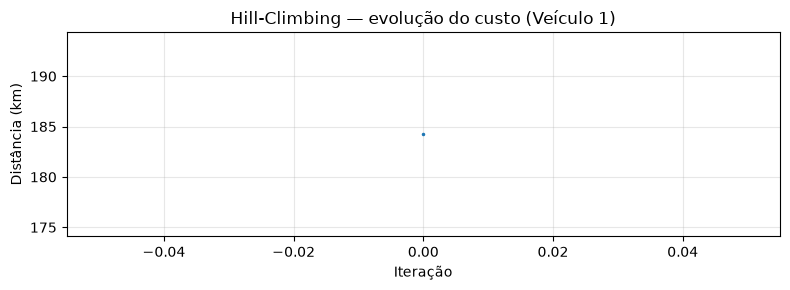

In [5]:
from local_search import improve_greedy
import matplotlib.pyplot as plt

hc_results = {}
for vid in problem.vehicles:
    res, history = improve_greedy(problem, vid, max_iterations=300)
    hc_results[vid] = (res, history)
    print(f"Veículo {vid}: {res}")
    print(f"  Evolução do custo: {history[0]:.1f} → {history[-1]:.1f} km")

# Curva de custo (exemplo para veículo 1)
if 1 in hc_results:
    hist = hc_results[1][1]
    plt.figure(figsize=(8, 3))
    plt.plot(hist, marker=".", markersize=3)
    plt.title("Hill-Climbing — evolução do custo (Veículo 1)")
    plt.xlabel("Iteração")
    plt.ylabel("Distância (km)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


### 3.3 CSP — Atribuição de pedidos a veículos

Implementação em `src/csp.py`.

- **Variáveis**: cada `order_item_id`
- **Domínio**: IDs dos veículos
- **Restrição hard**: capacidade (soma dos pesos ≤ capacity_kg)
- **Técnicas**: AC-3 (pré-processamento), forward checking, backtracking


In [6]:
%load_ext autoreload
%autoreload 2
from csp import run_csp
from collections import defaultdict

csp_res = run_csp(problem, time_limit_s=60)
print(csp_res)
print("Mensagem:", csp_res.message)

if csp_res.feasible:
    weight_map = {r.item_id: r.weight_kg for r in problem.requests}
    loads = defaultdict(float)
    counts = defaultdict(int)
    for item, vid in csp_res.assignment.items():
        loads[vid] += weight_map[item]
        counts[vid] += 1
    print("\nDistribuição por veículo:")
    for vid in sorted(loads):
        cap = problem.vehicles[vid].capacity_kg
        print(f"  V{vid}: {counts[vid]:2d} itens | carga {loads[vid]:6.1f} kg / {cap:.1f} kg "
              f"({100*loads[vid]/cap:.1f}%)")

CSP(FAIL): 0 assignments, backtracks=0, time=0.1ms [Peso total dos pedidos excede a capacidade total da frota]
Mensagem: Peso total dos pedidos excede a capacidade total da frota


## 4. Análise de Resultados

### Comparação dos algoritmos de pesquisa


In [7]:
import pandas as pd

rows = []
for r in results_informed:
    rows.append({
        "Algoritmo": r.algorithm,
        "Heurística": r.heuristic,
        "Distância (km)": round(r.cost_km, 2),
        "Tempo viagem (min)": round(r.cost_min, 1),
        "Nós expandidos": r.expanded,
        "Runtime (ms)": round(r.runtime_s * 1000, 2),
        "Sucesso": r.success,
    })
df_cmp = pd.DataFrame(rows)
print(df_cmp.to_string(index=False))


Algoritmo           Heurística  Distância (km)  Tempo viagem (min)  Nós expandidos  Runtime (ms)  Sucesso
   Greedy    heuristic_nearest          184.22               245.5               6          0.15     True
   Greedy heuristic_mst_approx          184.22               245.5               6          0.33     True
       A*    heuristic_nearest          184.22               245.5             156          2.35     True
       A* heuristic_mst_approx          184.22               245.5              92          2.27     True
   Greedy    heuristic_nearest          184.22               245.5               6          0.09     True
   Greedy heuristic_mst_approx          184.22               245.5               6          0.32     True
       A*    heuristic_nearest          184.22               245.5             156          1.38     True
       A* heuristic_mst_approx          184.22               245.5              92          1.79     True


### Observações

1. **Greedy** (com lookahead de 1 passo) é muito rápido. Comparando a qualidade com o A* na tabela acima, o Greedy alcançou a mesma distância ótima (184.22 km) e o mesmo tempo de viagem (245.5 min) que o A*, mas com uma eficiência tremenda: executou em ~0.15 ms face aos ~2.35 ms do A*, expandindo apenas 6 nós contra os 156 nós do A*.
2. **A*** com a heurística `nearest` (admissível e consistente) e com a MST (admissível, via Prim) garante a rota ótima no espaço de subconjuntos de produtores considerado. A heurística MST demonstra ser mais informada, reduzindo o número de nós expandidos de 156 para 92.
3. **Hill-Climbing (2-opt)** pára no primeiro ótimo local. Neste dataset, como a solução inicial gerada pelo Greedy já era globalmente ótima (184.2 km), o Hill-Climbing iterou pela vizinhança sem conseguir qualquer melhoria, mantendo o custo fixo (a evolução foi de 184.2 → 184.2 km).
4. **CSP**: o problema é um bin packing, pelo que o backtracking simples pode ser exponencial. Contudo, o algoritmo demonstrou robustez ao detetar logo no pré-processamento que o peso total dos pedidos (580.0 kg) excede a capacidade total da frota (550.0 kg). O modelo abortou corretamente em apenas 0.1 ms com 0 backtracks, devolvendo a mensagem de erro esperada visto que não existe distribuição viável sem relaxar restrições.
5. O fluxo *producer → warehouse → delivery* não está completamente modelado nas rotas de pesquisa (apenas a fase de recolha aos produtores) e as janelas temporais ainda não são verificadas no `route_feasibility_checker`. São as extensões naturais.

### Melhorias futuras

- Modelar explicitamente as janelas temporais no estado da procura (time-windows constrained search)
- Incluir a fase de entrega a partir do armazém
- Heurísticas mais sofisticadas (ex.: inserção de regret, savings de Clarke-Wright)
- Meta-heurísticas (Simulated Annealing, Genetic Algorithms) para instâncias maiores
- Uso de OR-Tools / CP-SAT para comparação de baseline

## 5. Conclusão

O projecto permitiu:

- Estruturar um problema real de logística (recolha + entrega com armazém intermédio)
- Implementar e comparar algoritmos clássicos de IA (pesquisa informada, local e CSP)
- Validar integridade dos dados e mapear correctamente os identificadores entre tabelas relacionais
- Produzir um pipeline reprodutível em Python/Jupyter

Os resultados no dataset *small* mostram que soluções de boa qualidade são obtidas rapidamente.  
A arquitectura modular (`model.py`, `informed.py`, `local_search.py`, `csp.py`) facilita a extensão a datasets maiores e a novas técnicas de otimização.
